In [1]:
from pathlib import Path
from zipfile import ZipFile
from io import BytesIO
import pandas as pd
import matplotlib.pyplot as plt

proyecto = Path.cwd()
if proyecto.name == "notebooks":
    proyecto = proyecto.parent

ruta = proyecto / "data" / "raw" / "beijing+multi+site+air+quality+data.zip"

with ZipFile(ruta) as archivo:
    zip_interno = archivo.read("PRSA2017_Data_20130301-20170228.zip")

tablas = []
with ZipFile(BytesIO(zip_interno)) as archivo:
    for nombre in archivo.namelist():
        if nombre.endswith(".csv"):
            tabla = pd.read_csv(archivo.open(nombre))
            tablas.append(tabla)

datos = pd.concat(tablas, ignore_index=True)
datos["fecha_hora"] = pd.to_datetime(datos[["year", "month", "day", "hour"]])

print("Archivos CSV:", len(tablas))
print("Filas y columnas:", datos.shape)
print("Estaciones:", datos["station"].nunique())
display(datos.head())

Archivos CSV: 12
Filas y columnas: (420768, 19)
Estaciones: 12


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,fecha_hora
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


In [2]:
print("Duplicados completos:", datos.duplicated().sum())
print("Horas duplicadas por estación:", datos.duplicated(["station", "fecha_hora"]).sum())

ordenados = datos.sort_values(["station", "fecha_hora"])
diferencias = ordenados.groupby("station")["fecha_hora"].diff().dropna()
print("Saltos distintos a una hora:", (diferencias != pd.Timedelta(hours=1)).sum())

faltantes = datos.isna().sum().sort_values(ascending=False)
display(pd.DataFrame({"faltantes": faltantes, "porcentaje": (datos.isna().mean() * 100).reindex(faltantes.index).round(2)}))

Duplicados completos: 0
Horas duplicadas por estación: 0
Saltos distintos a una hora: 0


,faltantes,porcentaje
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
TEMP,398,0.09
PRES,393,0.09


,size,count,mean,faltantes,porcentaje_nulos
station,,,,,
Wanliu,35064,34682,83.374716,382,1.09
Guanyuan,35064,34448,82.933372,616,1.76
Nongzhanguan,35064,34436,84.838483,628,1.79
Gucheng,35064,34418,83.852089,646,1.84
Tiantan,35064,34387,82.164911,677,1.93
Wanshouxigong,35064,34368,85.024136,696,1.98
Dongsi,35064,34314,86.194297,750,2.14
Changping,35064,34290,71.099743,774,2.21
Dingling,35064,34285,65.989497,779,2.22


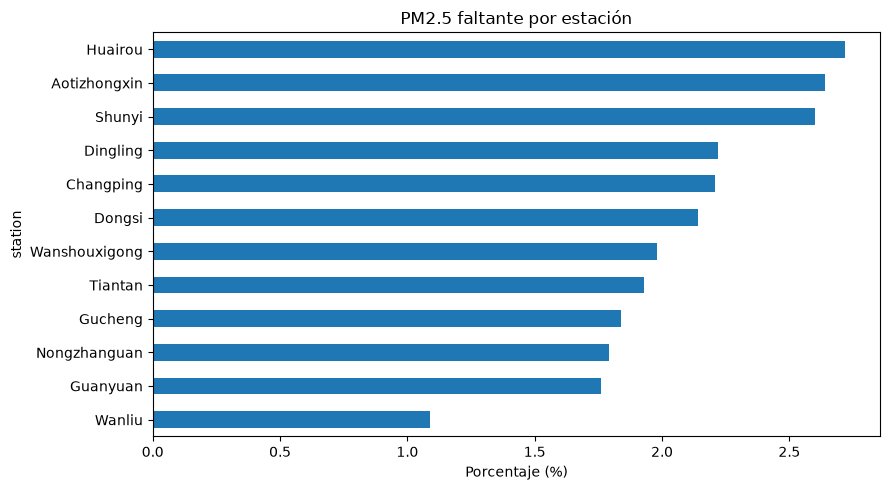

In [3]:
estaciones = datos.groupby("station")["PM2.5"].agg(["size", "count", "mean"])
estaciones["faltantes"] = estaciones["size"] - estaciones["count"]
estaciones["porcentaje_nulos"] = (estaciones["faltantes"] / estaciones["size"] * 100).round(2)
display(estaciones.sort_values("porcentaje_nulos"))

estaciones["porcentaje_nulos"].sort_values().plot(kind="barh", figsize=(9, 5))
plt.title("PM2.5 faltante por estación")
plt.xlabel("Porcentaje (%)")
plt.tight_layout()
plt.show()

In [4]:
wanliu = datos[datos["station"] == "Wanliu"].sort_values("fecha_hora").reset_index(drop=True)
print("Estación seleccionada: Wanliu")
print("Registros:", len(wanliu))
print("PM2.5 sin medición:", wanliu["PM2.5"].isna().sum())
print("Período:", wanliu["fecha_hora"].min(), "hasta", wanliu["fecha_hora"].max())

corte_train = wanliu["fecha_hora"].iloc[int(len(wanliu) * 0.70)]
exploracion = wanliu[wanliu["fecha_hora"] < corte_train].copy()
print("Análisis de relaciones en período de entrenamiento: hasta", corte_train)
display(wanliu[["fecha_hora", "PM2.5", "PM10", "TEMP", "wd"]].head())

Estación seleccionada: Wanliu
Registros: 35064
PM2.5 sin medición: 382
Período: 2013-03-01 00:00:00 hasta 2017-02-28 23:00:00
Análisis de relaciones en período de entrenamiento: hasta 2015-12-18 16:00:00


,fecha_hora,PM2.5,PM10,TEMP,wd
0,2013-03-01 00:00:00,8.0,8.0,-0.7,NNW
1,2013-03-01 01:00:00,9.0,9.0,-1.1,N
2,2013-03-01 02:00:00,3.0,6.0,-1.1,NNW
3,2013-03-01 03:00:00,11.0,30.0,-1.4,NW
4,2013-03-01 04:00:00,3.0,13.0,-2.0,N


count    24285.000000
mean        85.585460
std         79.664295
min          3.000000
25%         26.000000
50%         62.000000
75%        120.000000
max        718.000000
Name: PM2.5, dtype: float64

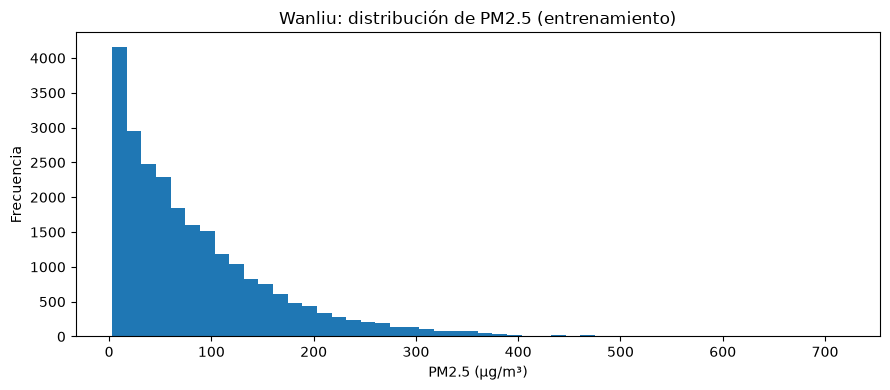

C:\Users\PC\AppData\Local\Temp\ipykernel_17292\524634869.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(exploracion["PM2.5"].dropna(), vert=False)


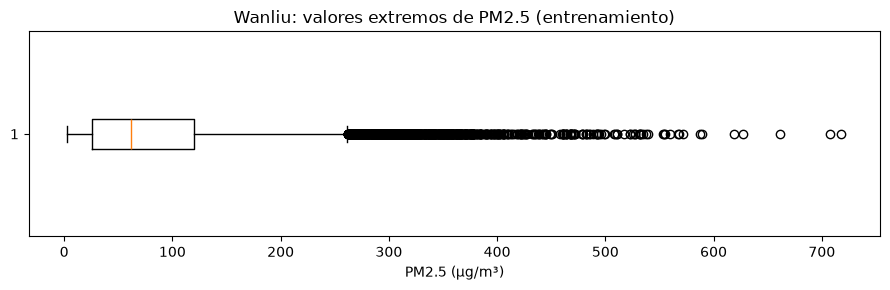

In [5]:
display(exploracion["PM2.5"].describe())

plt.figure(figsize=(9, 4))
plt.hist(exploracion["PM2.5"].dropna(), bins=50)
plt.title("Wanliu: distribución de PM2.5 (entrenamiento)")
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 3))
plt.boxplot(exploracion["PM2.5"].dropna(), vert=False)
plt.title("Wanliu: valores extremos de PM2.5 (entrenamiento)")
plt.xlabel("PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()

PM2.5    1.000
PM10     0.858
CO       0.732
NO2      0.635
SO2      0.513
DEWP     0.106
PRES     0.027
RAIN    -0.004
O3      -0.126
TEMP    -0.130
WSPM    -0.231
Name: PM2.5, dtype: float64

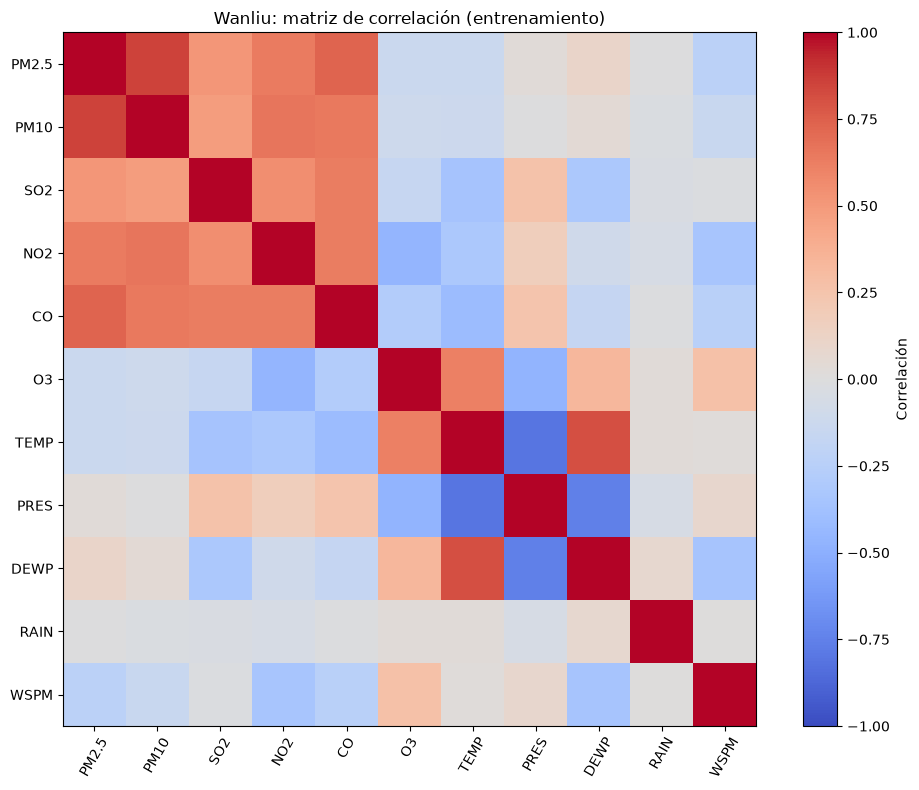

In [6]:
columnas = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
correlacion = exploracion[columnas].corr()

display(correlacion["PM2.5"].sort_values(ascending=False).round(3))

plt.figure(figsize=(10, 8))
plt.imshow(correlacion, vmin=-1, vmax=1, cmap="coolwarm")
plt.xticks(range(len(columnas)), columnas, rotation=60)
plt.yticks(range(len(columnas)), columnas)
plt.colorbar(label="Correlación")
plt.title("Wanliu: matriz de correlación (entrenamiento)")
plt.tight_layout()
plt.show()

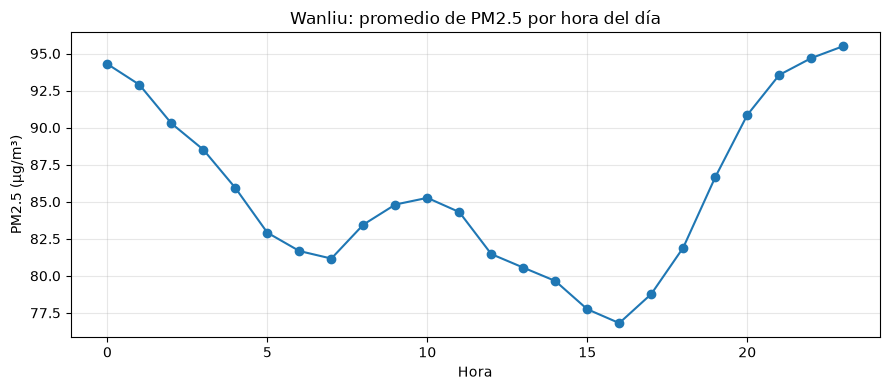

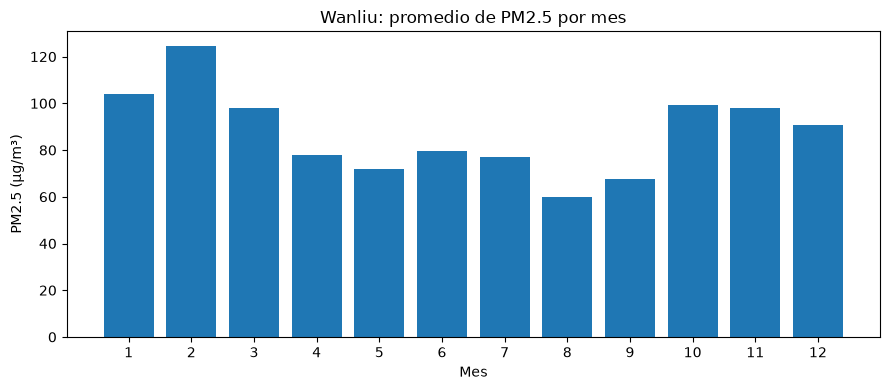

In [7]:
por_hora = exploracion.groupby("hour")["PM2.5"].mean()
por_mes = exploracion.groupby("month")["PM2.5"].mean()

plt.figure(figsize=(9, 4))
plt.plot(por_hora.index, por_hora.values, marker="o")
plt.title("Wanliu: promedio de PM2.5 por hora del día")
plt.xlabel("Hora")
plt.ylabel("PM2.5 (µg/m³)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.bar(por_mes.index, por_mes.values)
plt.title("Wanliu: promedio de PM2.5 por mes")
plt.xlabel("Mes")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

,horas_atrás,correlación
0,1,0.968
1,2,0.923
2,3,0.880
3,6,0.767
4,12,0.600
5,24,0.410
6,48,0.135


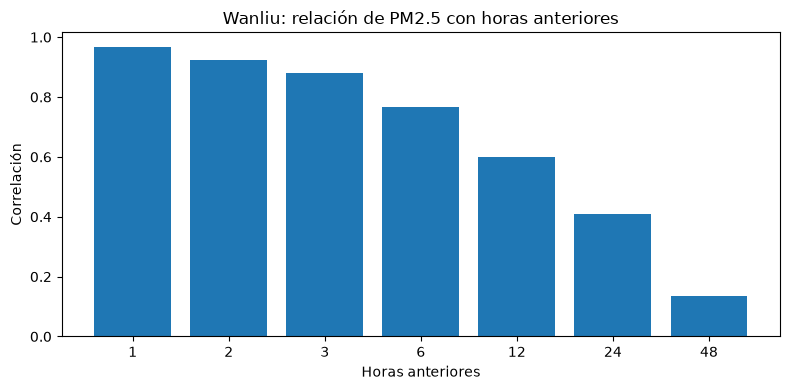

In [8]:
retrasos = [1, 2, 3, 6, 12, 24, 48]
valores = []

for horas in retrasos:
    correlacion = exploracion["PM2.5"].corr(exploracion["PM2.5"].shift(horas))
    valores.append(correlacion)

resultado = pd.DataFrame({"horas_atrás": retrasos, "correlación": valores})
display(resultado.round(3))

plt.figure(figsize=(8, 4))
plt.bar(resultado["horas_atrás"].astype(str), resultado["correlación"])
plt.title("Wanliu: relación de PM2.5 con horas anteriores")
plt.xlabel("Horas anteriores")
plt.ylabel("Correlación")
plt.tight_layout()
plt.show()

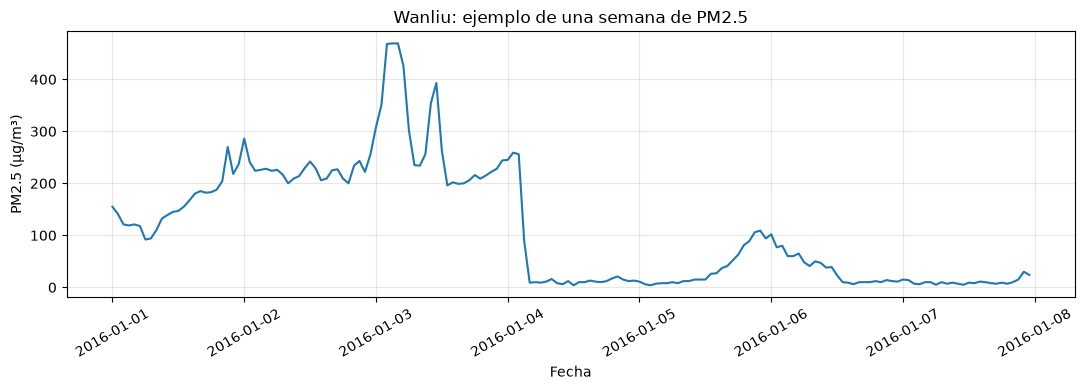

In [9]:
serie = wanliu.set_index("fecha_hora")["PM2.5"]

plt.figure(figsize=(11, 4))
plt.plot(serie.loc["2016-01-01":"2016-01-07"].index, serie.loc["2016-01-01":"2016-01-07"].values)
plt.title("Wanliu: ejemplo de una semana de PM2.5")
plt.xlabel("Fecha")
plt.ylabel("PM2.5 (µg/m³)")
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()